## 03 - Modeling: uplift Hillstrom (target `visit`)
Model dasar LightGBM di 7 fitur mentah: S-learner dan T-learner x setup A (treated vs control) dan setup B (Mens/Womens/control). Out-of-fold di `dev`, hold-out tidak disentuh.

### Load data dan bangun `dev`
`dev` = 44.800 baris (70%) yang boleh dipakai modeling, dengan kolom `fold` 0..4.
Hold-out (30%) sengaja TIDAK dimuat ke variabel apa pun di notebook ini.

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
import lightgbm as lgb
import matplotlib.pyplot as plt


ROOT = Path.cwd().parent
RAW_FILE = ROOT / "data" / "Kevin_Hillstrom_Dataset.csv"
SPLIT_FILE = ROOT / "data" / "split_hillstrom.csv"

raw = pd.read_csv(RAW_FILE)
split = pd.read_csv(SPLIT_FILE)

assert len(raw) == len(split), f"panjang beda: raw={len(raw)} split={len(split)}"
print("kolom di split file:", split.columns.tolist())   

full = raw.reset_index(drop=True).assign(split=split["split"].to_numpy(),
                                         fold=split["fold"].to_numpy())

dev = full[full["split"] == "dev"].reset_index(drop=True)   # label "dev": cek isi kolom split
del full                                                     # hold-out tidak dipakai lagi

kolom di split file: ['Unnamed: 0', 'split', 'fold']


In [2]:
assert len(dev) == 44_800, len(dev)
assert set(dev["fold"].unique()) == {0, 1, 2, 3, 4}, "fold dev harus 0..4 (tidak ada -1)"
assert dev["fold"].value_counts().nunique() == 1, "ukuran fold tidak sama"
assert abs(dev["visit"].mean() - 0.1468) < 5e-4, dev["visit"].mean()


rate = dev.groupby(["segment", "fold"])["visit"].mean().unstack("fold")
dev_rate = dev.groupby("segment")["visit"].mean()
max_dev = rate.sub(dev_rate, axis=0).abs().to_numpy().max()
print(rate.round(4)); print("selisih maks vs rata-rata arm:", round(max_dev, 4))
assert max_dev < 0.002, "split kemungkinan tidak sejajar dengan raw"

fold                0       1       2       3       4
segment                                              
Mens E-Mail    0.1827  0.1827  0.1827  0.1827  0.1830
No E-Mail      0.1059  0.1060  0.1063  0.1063  0.1063
Womens E-Mail  0.1516  0.1516  0.1513  0.1513  0.1513
selisih maks vs rata-rata arm: 0.0003


### Model dasar (LightGBM, 7 fitur mentah), out-of-fold di `dev`
Grid: {S-learner, T-learner} x {setup A (treated vs control), setup B (Mens/Womens/control)}.
Satu kali jalan. Hyperparameter DIKUNCI di bawah, tidak disetel setelah melihat skor.
Hold-out tidak disentuh.  

**PREDIKSI**:  
  Setup B: model vs P1 (CI selisih) -> Model lebih tinggi dari P1 positif di atas 0, bedanya gak jauh  
  Setup A: model vs skor 3 sel (CI selisih area) -> Model lebih tinggi, beda sedikit  
  S vs T: mana yang lebih baik, dan kenapa -> T learner, data seimabng sehingga ketika diuji dengan pengubahan seed skor lebih stabil

In [3]:
FEATURES = ["recency", "history", "mens", "womens", "zip_code", "newbie", "channel"]
CAT_COLS = ["zip_code", "channel"]
CONTROL, MENS, WOMENS = "No E-Mail", "Mens E-Mail", "Womens E-Mail"
ARMS = [CONTROL, MENS, WOMENS]
N_FOLDS = 5
SEED = 42

# Hyperparameter tetap (keputusan di awal, bukan hasil tuning).
# Kecil dan konservatif: efek uplift kecil, data berisik, mudah menghafal noise.
PARAMS = dict(
    objective="binary",
    learning_rate=0.03,
    n_estimators=300,
    num_leaves=8,
    min_child_samples=200,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=1.0,
    reg_lambda=5.0,
    n_jobs=-1,
    verbose=-1,
)

In [4]:
X = dev[FEATURES].copy()
for c in CAT_COLS:
    X[c] = X[c].astype("category")   

y = dev["visit"].to_numpy()
arm = dev["segment"].to_numpy()
folds = dev["fold"].to_numpy()
treated = (arm != CONTROL).astype(int)   

assert set(np.unique(arm)) == set(ARMS), "label segment tidak cocok dengan ARMS"
assert set(np.unique(folds)) == set(range(N_FOLDS)), "fold harus 0..4 di dev"
assert list(X.columns) == FEATURES

In [5]:
def run_all(seed, X=X, params=PARAMS):
    P = {**params, "random_state": seed}

    """Latih semua learner out-of-fold. Return dict skor uplift per baris dev.
    A: array (n,)  = uplift 'kirim apa pun' vs control
    B: array (n,2) = kolom 0 uplift Mens, kolom 1 uplift Womens (vs control)
    """

    def fit(Xf, yf):
        return lgb.LGBMClassifier(**P).fit(Xf, yf)

    def prob(m, Xf):
        return m.predict_proba(Xf)[:, 1]

    def arm_col(values):
        return pd.Categorical(values, categories=ARMS)

    n = len(dev)
    out = {
        "S_A": np.full(n, np.nan), "T_A": np.full(n, np.nan),
        "S_B": np.full((n, 2), np.nan), "T_B": np.full((n, 2), np.nan),
    }

    for k in range(N_FOLDS):
        te = np.where(folds == k)[0]
        tr = np.where(folds != k)[0]
        Xte = X.iloc[te]

        # ---- S-learner A: 1 model, fitur = 7 + treated ----
        m = fit(X.iloc[tr].assign(treated=treated[tr]), y[tr])
        out["S_A"][te] = (prob(m, Xte.assign(treated=1))
                          - prob(m, Xte.assign(treated=0)))

        # ---- S-learner B: 1 model, fitur = 7 + arm (kategori 3 level) ----
        m = fit(X.iloc[tr].assign(arm=arm_col(arm[tr])), y[tr])
        p = {a: prob(m, Xte.assign(arm=arm_col([a] * len(te)))) for a in ARMS}
        out["S_B"][te] = np.column_stack([p[MENS] - p[CONTROL], p[WOMENS] - p[CONTROL]])

        # ---- T-learner A: 2 model (treated gabungan, control), tanpa kolom arm ----
        idx1, idx0 = tr[treated[tr] == 1], tr[treated[tr] == 0]
        m1, m0 = fit(X.iloc[idx1], y[idx1]), fit(X.iloc[idx0], y[idx0])
        out["T_A"][te] = prob(m1, Xte) - prob(m0, Xte)

        # ---- T-learner B: 3 model, satu per arm ----
        p = {}
        for a in ARMS:
            idx = tr[arm[tr] == a]
            p[a] = prob(fit(X.iloc[idx], y[idx]), Xte)
        out["T_B"][te] = np.column_stack([p[MENS] - p[CONTROL], p[WOMENS] - p[CONTROL]])

    for name, s in out.items():
        assert not np.isnan(s).any(), f"{name}: ada baris tanpa skor out-of-fold"
    return out


scores = run_all(SEED)

In [6]:
# --- Kebijakan setup B dari skor uplift (n,2) ---
def policy_B(U, gate=False):
    """argmax uplift antara Mens/Womens. gate=True: kirim hanya kalau uplift terbaik > 0."""
    choice = np.where(U.argmax(1) == 0, MENS, WOMENS)
    if gate:
        choice = np.where(U.max(1) > 0, choice, CONTROL)
    return choice

policies_B = {
    "P1 Mens ke semua": np.full(len(dev), MENS),          # patokan yang harus dikalahkan
    "S_B argmax":       policy_B(scores["S_B"]),          # utama
    "T_B argmax":       policy_B(scores["T_B"]),          # utama
    "S_B argmax+gate":  policy_B(scores["S_B"], gate=True),  # diagnostik
    "T_B argmax+gate":  policy_B(scores["T_B"], gate=True),  # diagnostik
}

In [7]:
# --- Diagnostik cepat (bukan hasil): apakah skor menyusut ke nol / masuk akal? ---
ate_A = y[treated == 1].mean() - y[treated == 0].mean()
ate_M = y[arm == MENS].mean() - y[arm == CONTROL].mean()
ate_W = y[arm == WOMENS].mean() - y[arm == CONTROL].mean()
print(f"ATE dev  gabungan={ate_A:+.4f}  Mens={ate_M:+.4f}  Womens={ate_W:+.4f}\n")

for name in ["S_A", "T_A"]:
    s = scores[name]
    print(f"{name}: mean={s.mean():+.4f} (bandingkan ATE gabungan)  std={s.std():.4f}")
for name in ["S_B", "T_B"]:
    s = scores[name]
    print(f"{name}: mean Mens={s[:,0].mean():+.4f}  mean Womens={s[:,1].mean():+.4f}  "
          f"std Mens={s[:,0].std():.4f}  std Womens={s[:,1].std():.4f}")
for name, ch in policies_B.items():
    print(f"{name:18s} share Mens={np.mean(ch == MENS):.2f}  "
          f"Womens={np.mean(ch == WOMENS):.2f}  control={np.mean(ch == CONTROL):.2f}")

ATE dev  gabungan=+0.0609  Mens=+0.0766  Womens=+0.0453

S_A: mean=+0.0590 (bandingkan ATE gabungan)  std=0.0234
T_A: mean=+0.0603 (bandingkan ATE gabungan)  std=0.0371
S_B: mean Mens=+0.0746  mean Womens=+0.0441  std Mens=0.0211  std Womens=0.0274
T_B: mean Mens=+0.0765  mean Womens=+0.0448  std Mens=0.0413  std Womens=0.0467
P1 Mens ke semua   share Mens=1.00  Womens=0.00  control=0.00
S_B argmax         share Mens=0.88  Womens=0.12  control=0.00
T_B argmax         share Mens=0.74  Womens=0.26  control=0.00
S_B argmax+gate    share Mens=0.88  Womens=0.12  control=0.00
T_B argmax+gate    share Mens=0.73  Womens=0.26  control=0.02


In [8]:
N_BOOT = 1000                      
ARM_COL, TARGET = "segment", "visit"
CTRL, TR1, TR2 = CONTROL, MENS, WOMENS
_trapz = getattr(np, "trapezoid", None) or np.trapz

def evaluate_policies(y, arm, actions, prop, n_boot=N_BOOT, seed=SEED):
    """actions: dict nama -> array arm pilihan kebijakan untuk tiap baris."""
    y = np.asarray(y, float)
    arm = np.asarray(arm, object)
    p = pd.Series(arm).map(prop).to_numpy(float)
    W = np.column_stack([(arm == np.asarray(a, object)) / p for a in actions.values()])
    n = len(y)

    def est(ix):
        w = W[ix]
        return (w * y[ix, None]).sum(0) / w.sum(0)

    rng = np.random.default_rng(seed)
    point = est(np.arange(n))
    boots = np.array([est(rng.integers(0, n, n)) for _ in range(n_boot)])
    return list(actions), point, boots


def summarize(names, point, boots, refs):
    out = pd.DataFrame({"value": point}, index=names)
    out["ci_low"], out["ci_high"] = np.percentile(boots, [2.5, 97.5], axis=0)
    for r in refs:
        k = names.index(r)
        d = boots - boots[:, [k]]
        tag = r[:2]
        out[f"vs_{tag}"] = point - point[k]
        out[f"vs_{tag}_low"], out[f"vs_{tag}_high"] = np.percentile(d, [2.5, 97.5], axis=0)
    return out

def uplift_gain(y, t, score, ks=np.linspace(0.05, 1.0, 20), seed=0):
    y = np.asarray(y, float)
    t = np.asarray(t, int)
    s = np.asarray(score, float)
    n = len(y)
    order = np.lexsort((np.random.default_rng(seed).random(n), -s))   # skor kembar: urutan acak
    y, t = y[order], t[order]
    cy_t, cy_c = np.cumsum(y * t), np.cumsum(y * (1 - t))
    cn_t, cn_c = np.cumsum(t), np.cumsum(1 - t)
    i = np.ceil(ks * n).astype(int) - 1
    gain = (cy_t[i] / cn_t[i] - cy_c[i] / cn_c[i]) * ks
    area = _trapz(gain - ks * gain[-1], ks)
    return ks, gain, area

def paired_diff(names, point, boots, a, b):
    i, j = names.index(a), names.index(b)
    lo, hi = np.percentile(boots[:, i] - boots[:, j], [2.5, 97.5])
    return point[i] - point[j], lo, hi



### Setup B

In [9]:
prop = dev[ARM_COL].value_counts(normalize=True).to_dict()
names, point, boots = evaluate_policies(y, arm, policies_B, prop)

# cek salinan benar: value P1 harus 0.1828
i1 = names.index("P1 Mens ke semua")
assert np.isclose(point[i1], y[arm == MENS].mean())

res_B = summarize(names, point, boots, refs=["P1 Mens ke semua"])
print(res_B.round(4))

print("S - T:", [round(v, 4) for v in paired_diff(names, point, boots, "S_B argmax", "T_B argmax")])

                   value  ci_low  ci_high   vs_P1  vs_P1_low  vs_P1_high
P1 Mens ke semua  0.1828  0.1771   0.1889  0.0000     0.0000      0.0000
S_B argmax        0.1841  0.1779   0.1901  0.0013    -0.0017      0.0040
T_B argmax        0.1789  0.1728   0.1853 -0.0039    -0.0084      0.0004
S_B argmax+gate   0.1841  0.1779   0.1901  0.0013    -0.0017      0.0040
T_B argmax+gate   0.1772  0.1710   0.1831 -0.0056    -0.0102     -0.0014
S - T: [np.float64(0.0052), np.float64(0.0016), np.float64(0.009)]


- Tidak ada model yang terbukti mengalahkan P1 (kirim Mens ke semua). 
- S_B selisihnya kecil dan belum terbukti, T_B belum terbukti tapi condong lebih buruk, dan T_B+gate terbukti lebih buruk. 
- Antar model, S_B unggul atas T_B di seed 42 ini; apakah itu bertahan di seed lain dicek di bawah (5 seed).

### Setup A

In [10]:
# skor 3 sel cross-fit, versi lokal (tanpa menulis ke dev)
cd = dev[["mens", "womens"]].assign(t=treated, y=y, f=folds)
score_3 = np.full(len(dev), np.nan)
for f in range(N_FOLDS):
    g = cd[cd.f != f].groupby(["mens", "womens", "t"])["y"].mean().unstack("t")
    te = np.where(cd.f == f)[0]
    cells = pd.MultiIndex.from_frame(cd.iloc[te][["mens", "womens"]])
    score_3[te] = (g[1] - g[0]).reindex(cells).to_numpy()
assert not np.isnan(score_3).any()

def areas_paired(y, t, scores, n_boot=500, seed=SEED):
    y, t = np.asarray(y), np.asarray(t)
    S = {k: np.asarray(v) for k, v in scores.items()}
    n = len(y)
    point = {k: uplift_gain(y, t, s)[2] for k, s in S.items()}
    rng = np.random.default_rng(seed)
    b = {k: [] for k in S}
    for _ in range(n_boot):
        ix = rng.integers(0, n, n)              
        for k, s in S.items():
            b[k].append(uplift_gain(y[ix], t[ix], s[ix])[2])
    return point, {k: np.array(v) for k, v in b.items()}

pt, bt = areas_paired(y, treated, {"S_A": scores["S_A"], "T_A": scores["T_A"], "3 sel": score_3})

rows = []
for a, b_ in [("S_A", "3 sel"), ("T_A", "3 sel"), ("S_A", "T_A")]:
    lo, hi = np.percentile(bt[a] - bt[b_], [2.5, 97.5])
    rows.append((f"{a} - {b_}", pt[a] - pt[b_], lo, hi))
print(pd.DataFrame(rows, columns=["pasangan", "selisih_area", "low", "high"]).round(4))

      pasangan  selisih_area     low    high
0  S_A - 3 sel        0.0005 -0.0006  0.0017
1  T_A - 3 sel       -0.0008 -0.0027  0.0010
2    S_A - T_A        0.0013 -0.0003  0.0028


### Visualisasi Setup A

In [11]:
def curve(y, t, s, seed=0):
    """Kurva untuk satu skor. Menambahkan titik (0,0) di awal.
    Return: ks, gain, selisih (gain - garis acak), area."""
    ks, gain, area = uplift_gain(y, t, s, seed=seed)
    ks, gain = np.r_[0.0, ks], np.r_[0.0, gain]
    garis_acak = ks * gain[-1]            # garis lurus dari (0,0) ke ujung kanan (ATE gabungan)
    return ks, gain, gain - garis_acak, area


def curve_band(y, t, scores, n_boot=300, seed=SEED):
    """Pita CI 95% untuk (gain - garis acak), bootstrap baris.
    Satu resample dipakai untuk semua skor (berpasangan), sama seperti areas_paired."""
    y, t = np.asarray(y), np.asarray(t)
    S = {k: np.asarray(v, float) for k, v in scores.items()}
    n = len(y)
    rng = np.random.default_rng(seed)
    d = {k: [] for k in S}
    for _ in range(n_boot):
        ix = rng.integers(0, n, n)
        for k, s in S.items():
            d[k].append(curve(y[ix], t[ix], s[ix])[2])
    return {k: np.percentile(np.array(v), [2.5, 97.5], axis=0) for k, v in d.items()}


def plot_uplift(y, t, scores, title, n_boot=300):
    """scores: dict nama -> array skor uplift (satu skor per baris, urutan sama dengan y dan t)."""
    y, t = np.asarray(y, float), np.asarray(t, int)
    for k, v in scores.items():
        assert len(v) == len(y) and not np.isnan(np.asarray(v, float)).any(), f"{k}: skor bermasalah"

    ks, _, _, _ = curve(y, t, next(iter(scores.values())))
    band = curve_band(y, t, scores, n_boot=n_boot)
    ate = y[t == 1].mean() - y[t == 0].mean()

    fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
    for k, s in scores.items():
        ks, gain, dif, area = curve(y, t, s)
        lab = f"{k} (area {area:+.4f})"
        ax[0].plot(ks, gain, marker="o", ms=3, label=lab)
        line, = ax[1].plot(ks, dif, marker="o", ms=3, label=lab)
        lo, hi = band[k]
        ax[1].fill_between(ks, lo, hi, color=line.get_color(), alpha=0.15)

    # panel kiri: kurva gain + garis acak
    ax[0].plot([0, 1], [0, ate], "--", color="gray", label=f"acak (ujung = ATE {ate:+.4f})")
    ax[0].set(title="Gain kumulatif", xlabel="Proporsi pelanggan dikirimi email (urut skor menurun)",
              ylabel="(visit rate treated - control) x proporsi")
    ax[0].legend(); ax[0].grid(alpha=0.3)

    # panel kanan: selisih terhadap garis acak + pita CI
    ax[1].axhline(0, ls="--", color="gray")
    ax[1].set(title="Selisih terhadap garis acak (pita = CI 95% bootstrap)",
              xlabel="Proporsi pelanggan dikirimi email", ylabel="gain - garis acak")
    ax[1].legend(); ax[1].grid(alpha=0.3)

    fig.suptitle(title)
    fig.tight_layout()
    return fig


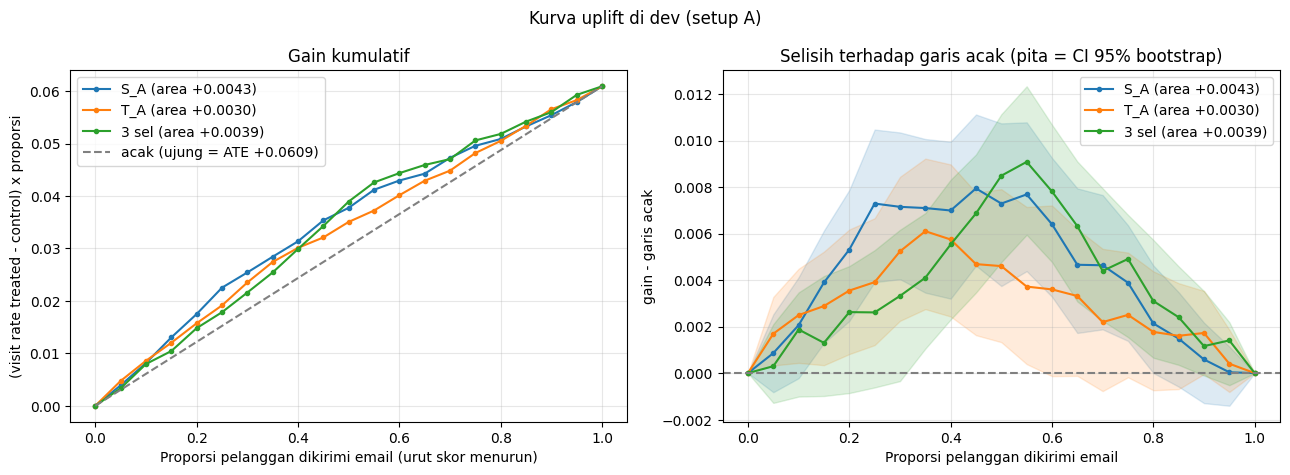

In [12]:
# ---- DEV (out-of-fold; model = 7 fitur dasar, seed SEED) ----
fig_dev = plot_uplift(
    y, treated,
    {"S_A": scores["S_A"], "T_A": scores["T_A"], "3 sel": score_3},
    title="Kurva uplift di dev (setup A)")
plt.show()


Di dev (out-of-fold), tidak ada model yang terbukti mengurutkan pelanggan lebih baik dari tabel 3 sel. Ketiganya sedikit di atas urutan acak.

| Skor | Area |
| --- | --- |
| S-learner (S_A) | +0,0043 |
| T-learner (T_A) | +0,0030 |
| Tabel 3 sel | +0,0039 |

**Cara membaca kurva.** Pelanggan diurutkan dari skor tertinggi ke terendah, lalu dihitung kenaikan visit rate populasi kalau email hanya dikirim ke top-k. Garis putus-putus adalah memilih sembarang (k × ATE). Selisih antara tiap kurva dan garis itu (panel kanan) menunjukkan seberapa besar keunggulan urutan skor di tiap k. Ketiga kurva bertemu di k = 1 (ATE gabungan ≈ 0,061), karena kalau semua dikirimi, urutan tidak berpengaruh.

**Hasil.** Ketiga kurva berada di atas garis acak di sebagian besar k, dengan selisih puncak sekitar 0,008 sampai 0,009. S_A berada sedikit di atas tabel dan T_A sedikit di bawahnya, tetapi pita CI ketiganya saling tumpang tindih. Perbandingan model vs tabel memakai CI selisih berpasangan (ringkasan 5 seed): belum terbukti di 5/5 seed.

**Catatan.** Area tidak menunjukkan k terbaik; ia meringkas keunggulan di semua k. Interval hanya mengukur noise penilaian, bukan noise pelatihan.

In [13]:
def eval_seed(sd):
    sc = run_all(sd)
    pol = {"P1": np.full(len(dev), MENS),
           "S_B": policy_B(sc["S_B"]),
           "T_B": policy_B(sc["T_B"])}
    names, point, boots = evaluate_policies(y, arm, pol, prop)

    row = {"seed": sd}
    for a, b in [("S_B", "P1"), ("T_B", "P1"), ("S_B", "T_B")]:
        d, lo, hi = paired_diff(names, point, boots, a, b)
        row[f"{a} - {b}"] = f"{d:+.4f} [{lo:+.4f}; {hi:+.4f}]"

    pt, bt = areas_paired(y, treated, {"S_A": sc["S_A"], "T_A": sc["T_A"], "3 sel": score_3})
    for a, b in [("S_A", "3 sel"), ("T_A", "3 sel"), ("S_A", "T_A")]:
        lo, hi = np.percentile(bt[a] - bt[b], [2.5, 97.5])
        row[f"{a} - {b}"] = f"{pt[a]-pt[b]:+.4f} [{lo:+.4f}; {hi:+.4f}]"
    return row

rows = [eval_seed(sd) for sd in [42, 5, 11, 2026, 26]]
pd.DataFrame(rows).set_index("seed")

,S_B - P1,T_B - P1,S_B - T_B,S_A - 3 sel,T_A - 3 sel,S_A - T_A
seed,,,,,,
42,+0.0013 [-0.0017; +0.0040],-0.0039 [-0.0084; +0.0004],+0.0052 [+0.0016; +0.0090],+0.0005 [-0.0006; +0.0017],-0.0008 [-0.0027; +0.0010],+0.0013 [-0.0003; +0.0028]
5,+0.0011 [-0.0018; +0.0038],-0.0047 [-0.0092; -0.0005],+0.0058 [+0.0023; +0.0096],+0.0002 [-0.0009; +0.0013],-0.0009 [-0.0029; +0.0010],+0.0010 [-0.0004; +0.0025]
11,-0.0004 [-0.0033; +0.0024],-0.0036 [-0.0080; +0.0006],+0.0031 [-0.0005; +0.0066],-0.0000 [-0.0010; +0.0012],-0.0007 [-0.0027; +0.0011],+0.0007 [-0.0008; +0.0023]
2026,-0.0011 [-0.0038; +0.0015],-0.0040 [-0.0087; +0.0001],+0.0030 [-0.0008; +0.0068],+0.0003 [-0.0007; +0.0016],-0.0009 [-0.0027; +0.0010],+0.0013 [-0.0001; +0.0029]
26,-0.0007 [-0.0035; +0.0021],-0.0025 [-0.0070; +0.0015],+0.0019 [-0.0017; +0.0055],+0.0003 [-0.0008; +0.0016],-0.0008 [-0.0028; +0.0011],+0.0011 [-0.0003; +0.0028]


**Ringkasan 5 seed (7 fitur dasar, sebelum FE).** Selisih berpasangan, CI95 bootstrap.

- **S_B vs P1:** belum terbukti di 5/5 seed, titik berganti tanda (-0,0011 s/d +0,0013). Setara P1, tanpa bukti nilai tambah.
- **T_B vs P1:** belum terbukti di 4/5, kalah di 1/5 (seed 5). Titik negatif di kelima seed (-0,0047 s/d -0,0025), jadi condong lebih buruk dari P1.
- **S_B vs T_B:** unggul di 2/5 seed (42 dan 5), titik positif di kelima seed (+0,0019 s/d +0,0058). S condong lebih baik dari T, tetapi belum bisa dipegang.
- **Setup A (area kurva):** semua perbandingan belum terbukti di 5/5 seed. S_A ≈ tabel 3 sel (titik -0,0000 s/d +0,0005), T_A sedikit di bawahnya (-0,0009 s/d -0,0007).

Jadi: tidak ada model yang terbukti mengalahkan P1 (B) maupun tabel 3 sel (A). Interval hanya mengukur noise penilaian, bukan noise pelatihan.

---
## Rekayasa fitur (Feature Engineering)
Satu perubahan per eksperimen, dimulai dari 7 fitur dasar, 5 seed, `min_child_samples` = 200 (hyperparameter lain terkunci). Setiap eksperimen memakai rumus per baris (tanpa label, tanpa cross-fit), jadi tidak ada kebocoran.

Ketiganya eksplorasi (EDA tidak menunjukkan heterogenitas di fitur-fitur ini selain `mens`/`womens`):

- **FE-1**: `history / recency`. Dugaan: pelanggan yang belanjanya besar tapi baru-baru ini aktif lebih responsif ke email.
- **FE-3**: `mens + womens` (nilainya 1 atau 2; nilai 2 identik dengan sel (1,1)).
- **FE-2**: `zip_code × channel` (9 level). Dugaan: efek email berbeda tergantung wilayah dan kanal pembelian.

Urutan sel di bawah mengikuti urutan eksperimen dijalankan (FE-1, FE-3, FE-2).

### FE-1 `history/recency`

In [14]:
# --- FE-1: history / recency (rumus per baris, tanpa label, tanpa cross-fit) ---
X_fe = X.copy()
X_fe["hist_per_rec"] = dev["history"].to_numpy() / dev["recency"].to_numpy()

assert (dev["recency"] > 0).all()
assert np.isfinite(X_fe["hist_per_rec"]).all()
assert list(X_fe.index) == list(dev.index)
assert list(X_fe.columns) == FEATURES + ["hist_per_rec"]
assert list(X.columns) == FEATURES          # X lama tidak berubah


def eval_seed_X(sd, Xm):
    sc = run_all(sd, Xm)
    pol = {"P1": np.full(len(dev), MENS),
           "S_B": policy_B(sc["S_B"]),
           "T_B": policy_B(sc["T_B"])}
    names, point, boots = evaluate_policies(y, arm, pol, prop)

    row = {"seed": sd}
    for a, b in [("S_B", "P1"), ("T_B", "P1"), ("S_B", "T_B")]:
        d, lo, hi = paired_diff(names, point, boots, a, b)
        row[f"{a} - {b}"] = f"{d:+.4f} [{lo:+.4f}; {hi:+.4f}]"

    pt, bt = areas_paired(y, treated, {"S_A": sc["S_A"], "T_A": sc["T_A"], "3 sel": score_3})
    for a, b in [("S_A", "3 sel"), ("T_A", "3 sel"), ("S_A", "T_A")]:
        lo, hi = np.percentile(bt[a] - bt[b], [2.5, 97.5])
        row[f"{a} - {b}"] = f"{pt[a]-pt[b]:+.4f} [{lo:+.4f}; {hi:+.4f}]"
    return row


# CEK REPRODUKSI. HARUS SAMA DENGAN SEBELUMNYA SEED 42
chk = eval_seed_X(42, X)
print(chk)
# harus: S_B - P1 = +0.0013 [-0.0017; +0.0040]
#        T_B - P1 = -0.0039 [-0.0084; +0.0004]
#        S_A - 3 sel = +0.0005 [-0.0006; +0.0017]

{'seed': 42, 'S_B - P1': '+0.0013 [-0.0017; +0.0040]', 'T_B - P1': '-0.0039 [-0.0084; +0.0004]', 'S_B - T_B': '+0.0052 [+0.0016; +0.0090]', 'S_A - 3 sel': '+0.0005 [-0.0006; +0.0017]', 'T_A - 3 sel': '-0.0008 [-0.0027; +0.0010]', 'S_A - T_A': '+0.0013 [-0.0003; +0.0028]'}


In [15]:
rows_fe1 = [eval_seed_X(sd, X_fe) for sd in [42, 5, 11, 2026, 26]]
pd.DataFrame(rows_fe1).set_index("seed")

,S_B - P1,T_B - P1,S_B - T_B,S_A - 3 sel,T_A - 3 sel,S_A - T_A
seed,,,,,,
42,+0.0002 [-0.0028; +0.0030],-0.0039 [-0.0084; +0.0003],+0.0041 [+0.0004; +0.0080],-0.0002 [-0.0013; +0.0011],-0.0010 [-0.0030; +0.0009],+0.0008 [-0.0007; +0.0025]
5,+0.0006 [-0.0021; +0.0032],-0.0055 [-0.0099; -0.0013],+0.0061 [+0.0025; +0.0098],+0.0003 [-0.0008; +0.0016],-0.0015 [-0.0034; +0.0004],+0.0018 [+0.0003; +0.0034]
11,-0.0003 [-0.0029; +0.0023],-0.0049 [-0.0093; -0.0006],+0.0045 [+0.0010; +0.0082],+0.0001 [-0.0010; +0.0013],-0.0013 [-0.0033; +0.0006],+0.0014 [-0.0001; +0.0030]
2026,-0.0001 [-0.0031; +0.0030],-0.0051 [-0.0096; -0.0009],+0.0050 [+0.0012; +0.0086],+0.0001 [-0.0010; +0.0013],-0.0014 [-0.0033; +0.0005],+0.0014 [-0.0000; +0.0029]
26,-0.0000 [-0.0028; +0.0029],-0.0039 [-0.0084; +0.0001],+0.0039 [+0.0006; +0.0076],-0.0001 [-0.0012; +0.0012],-0.0012 [-0.0031; +0.0007],+0.0012 [-0.0003; +0.0028]


**Ringkasan FE-1 (rasio history/recency), 5 seed.** Selisih berpasangan, CI95 bootstrap.

- **S_B vs P1:** belum terbukti di 5/5 seed, titik berganti tanda (-0,0003 s/d +0,0006). Setara P1, **FE-1 tidak menambah nilai**.
- **T_B vs P1:** kalah di 3/5 seed (5, 11, 2026), belum terbukti di 2/5 (42 dan 26, batas atas hanya +0,0003 dan +0,0001). Titik negatif di kelima seed (-0,0055 s/d -0,0039), jadi condong **lebih buruk dari P1**.
- **S_B vs T_B:** unggul di 5/5 seed, titik positif (+0,0039 s/d +0,0061). **Ini lebih karena T melemah, bukan bukti S unggul**.
- **Setup A (area kurva):** S_A vs 3 sel dan T_A vs 3 sel belum terbukti di 5/5 seed. S_A ≈ tabel 3 sel (titik -0,0002 s/d +0,0003), T_A sedikit di bawahnya (-0,0015 s/d -0,0010). S_A vs T_A unggul hanya di 1/5 seed (seed 5), titik positif di kelima seed (+0,0008 s/d +0,0018).

Jadi: FE-1 tidak mengalahkan P1 (B) maupun tabel 3 sel (A), dan T cenderung memburuk. Interval hanya mengukur noise penilaian, bukan noise pelatihan.

### FE-3 `mens + womens`

In [16]:
# --- FE-3: mens + womens (rumus per baris, tanpa label, tanpa cross-fit) ---
X_fe3 = X.copy()
X_fe3["mw_sum"] = dev["mens"].to_numpy() + dev["womens"].to_numpy()

assert set(np.unique(X_fe3["mw_sum"])) == {1, 2}      # nilai 0 tidak ada di data
assert list(X_fe3.index) == list(dev.index)
assert list(X_fe3.columns) == FEATURES + ["mw_sum"]
assert list(X.columns) == FEATURES                     # X lama tidak berubah

rows_fe3 = [eval_seed_X(sd, X_fe3) for sd in [42, 5, 11, 2026, 26]]
pd.DataFrame(rows_fe3).set_index("seed")

,S_B - P1,T_B - P1,S_B - T_B,S_A - 3 sel,T_A - 3 sel,S_A - T_A
seed,,,,,,
42,+0.0017 [-0.0003; +0.0038],-0.0036 [-0.0081; +0.0006],+0.0053 [+0.0014; +0.0095],+0.0001 [-0.0011; +0.0015],-0.0006 [-0.0026; +0.0013],+0.0008 [-0.0005; +0.0021]
5,+0.0010 [-0.0007; +0.0028],-0.0049 [-0.0094; -0.0009],+0.0059 [+0.0020; +0.0100],+0.0001 [-0.0012; +0.0016],-0.0008 [-0.0027; +0.0010],+0.0009 [-0.0004; +0.0022]
11,-0.0002 [-0.0021; +0.0017],-0.0031 [-0.0077; +0.0010],+0.0029 [-0.0008; +0.0069],+0.0001 [-0.0011; +0.0016],-0.0004 [-0.0023; +0.0015],+0.0005 [-0.0008; +0.0019]
2026,+0.0008 [-0.0009; +0.0025],-0.0045 [-0.0090; -0.0006],+0.0053 [+0.0017; +0.0095],+0.0004 [-0.0009; +0.0018],-0.0007 [-0.0026; +0.0012],+0.0010 [-0.0002; +0.0024]
26,+0.0010 [-0.0011; +0.0030],-0.0036 [-0.0080; +0.0005],+0.0045 [+0.0006; +0.0087],+0.0002 [-0.0010; +0.0016],-0.0007 [-0.0027; +0.0012],+0.0009 [-0.0004; +0.0024]


**Ringkasan FE-3 (mens + womens), 5 seed.** Selisih berpasangan, CI95 bootstrap.

- **S_B vs P1:** belum terbukti di 5/5 seed. Titik positif di 4/5 seed (-0,0002 s/d +0,0017), tetapi semua CI memuat nol. Setara P1, tanpa bukti nilai tambah.
- **T_B vs P1:** kalah di 2/5 seed (5 dan 2026), belum terbukti di 3/5 (42, 11, 26). Titik negatif di kelima seed (-0,0049 s/d -0,0031), jadi condong lebih buruk dari P1.
- **S_B vs T_B:** unggul di 4/5 seed (belum terbukti di seed 11), titik positif di kelima seed (+0,0029 s/d +0,0059). Ini lebih karena T melemah, bukan bukti S unggul.
- **Setup A (area kurva):** semua perbandingan belum terbukti di 5/5 seed. S_A ≈ tabel 3 sel (titik +0,0001 s/d +0,0004), T_A sedikit di bawahnya (-0,0008 s/d -0,0004), S_A vs T_A positif di kelima seed (+0,0005 s/d +0,0010).

Jadi: FE-3 tidak mengalahkan P1 (B) maupun tabel 3 sel (A). Interval hanya mengukur noise penilaian, bukan noise pelatihan.

### FE-2 `zip_code x channel`

In [17]:
# --- FE-2: zip_code x channel (rumus per baris, tanpa label, tanpa cross-fit) ---
X_fe2 = X.copy()
X_fe2["zip_channel"] = (dev["zip_code"].astype(str) + "_" + dev["channel"].astype(str)).astype("category")

assert X_fe2["zip_channel"].nunique() == 9, X_fe2["zip_channel"].nunique()   # 3 x 3 kombinasi
assert list(X_fe2.index) == list(dev.index)
assert list(X_fe2.columns) == FEATURES + ["zip_channel"]
assert list(X.columns) == FEATURES                                            # X lama tidak berubah

print(X_fe2["zip_channel"].value_counts())   # ukuran tiap sel, untuk dibaca bersama hasilnya

rows_fe2 = [eval_seed_X(sd, X_fe2) for sd in [42, 5, 11, 2026, 26]]
pd.DataFrame(rows_fe2).set_index("seed")

zip_channel
Surburban_Web             8928
Surburban_Phone           8747
Urban_Phone               7947
Urban_Web                 7901
Rural_Web                 2998
Rural_Phone               2934
Surburban_Multichannel    2375
Urban_Multichannel        2172
Rural_Multichannel         798
Name: count, dtype: int64


,S_B - P1,T_B - P1,S_B - T_B,S_A - 3 sel,T_A - 3 sel,S_A - T_A
seed,,,,,,
42,+0.0012 [-0.0018; +0.0041],-0.0048 [-0.0096; -0.0006],+0.0060 [+0.0025; +0.0100],-0.0002 [-0.0013; +0.0011],-0.0011 [-0.0031; +0.0007],+0.0009 [-0.0006; +0.0023]
5,+0.0008 [-0.0019; +0.0034],-0.0038 [-0.0084; +0.0004],+0.0046 [+0.0013; +0.0087],-0.0003 [-0.0013; +0.0009],-0.0012 [-0.0033; +0.0007],+0.0009 [-0.0006; +0.0025]
11,-0.0007 [-0.0037; +0.0018],-0.0021 [-0.0070; +0.0022],+0.0014 [-0.0024; +0.0051],-0.0005 [-0.0015; +0.0008],-0.0011 [-0.0032; +0.0008],+0.0007 [-0.0008; +0.0023]
2026,+0.0001 [-0.0029; +0.0027],-0.0036 [-0.0082; +0.0005],+0.0037 [+0.0004; +0.0075],-0.0003 [-0.0014; +0.0010],-0.0013 [-0.0033; +0.0005],+0.0010 [-0.0004; +0.0025]
26,-0.0005 [-0.0033; +0.0021],-0.0028 [-0.0075; +0.0014],+0.0023 [-0.0014; +0.0065],-0.0000 [-0.0012; +0.0013],-0.0012 [-0.0033; +0.0005],+0.0012 [-0.0002; +0.0028]


**Ringkasan FE-2 (zip_code × channel, 9 level), 5 seed.** Selisih berpasangan, CI95 bootstrap.

- **S_B vs P1:** belum terbukti di 5/5 seed, titik berganti tanda (-0,0007 s/d +0,0012). Setara P1, FE-2 tidak menambah nilai.
- **T_B vs P1:** kalah di 1/5 seed (42), belum terbukti di 4/5. Titik negatif di kelima seed (-0,0048 s/d -0,0021), jadi condong lebih buruk dari P1.
- **S_B vs T_B:** unggul di 3/5 seed (42, 5, 2026), belum terbukti di 2/5 (11 dan 26). Titik positif di kelima seed (+0,0014 s/d +0,0060). Ini lebih karena T melemah, bukan bukti S unggul.
- **Setup A (area kurva):** semua perbandingan belum terbukti di 5/5 seed. S_A ≈ tabel 3 sel (titik -0,0005 s/d -0,0000), T_A sedikit di bawahnya (-0,0013 s/d -0,0011), S_A vs T_A positif di kelima seed (+0,0007 s/d +0,0012).

Jadi: FE-2 tidak mengalahkan P1 (B) maupun tabel 3 sel (A). Interval hanya mengukur noise penilaian, bukan noise pelatihan.

---
## Tuning satu hyperparameter
`min_child_samples` = 1000 / 200 / 50 pada FE-3, 5 seed per nilai (15 jalan), hanya di dev, tanpa memilih pemenang. Sel pertama mengecek reproduksi: setelan 200 + FE-3 + seed 42 harus cocok dengan tabel FE-3.

In [18]:
def eval_seed_P(sd, Xm, params):
    sc = run_all(sd, Xm, params)
    pol = {"P1": np.full(len(dev), MENS),
           "S_B": policy_B(sc["S_B"]),
           "T_B": policy_B(sc["T_B"])}
    names, point, boots = evaluate_policies(y, arm, pol, prop)

    row = {"seed": sd}
    for a, b in [("S_B", "P1"), ("T_B", "P1"), ("S_B", "T_B")]:
        d, lo, hi = paired_diff(names, point, boots, a, b)
        row[f"{a} - {b}"] = f"{d:+.4f} [{lo:+.4f}; {hi:+.4f}]"
    row["share W S_B"] = round(float(np.mean(pol["S_B"] == WOMENS)), 2)
    row["share W T_B"] = round(float(np.mean(pol["T_B"] == WOMENS)), 2)
    return row

# Cek reproduksi: setelan 200 + X_fe3 + seed 42 harus sama dengan tabel FE-3
chk = eval_seed_P(42, X_fe3, {**PARAMS, "min_child_samples": 200})
print(chk)
# harus: S_B - P1 = +0.0017 [-0.0003; +0.0038]
#        T_B - P1 = -0.0036 [-0.0081; +0.0006]

{'seed': 42, 'S_B - P1': '+0.0017 [-0.0003; +0.0038]', 'T_B - P1': '-0.0036 [-0.0081; +0.0006]', 'S_B - T_B': '+0.0053 [+0.0014; +0.0095]', 'share W S_B': 0.07, 'share W T_B': 0.27}


In [19]:
grid = {"mcs=1000": 1000, "mcs=200": 200, "mcs=50": 50}
all_rows = []
for tag, mcs in grid.items():
    prm = {**PARAMS, "min_child_samples": mcs}
    for sd in [42, 5, 11, 2026, 26]:
        r = eval_seed_P(sd, X_fe3, prm)
        r["setelan"] = tag
        all_rows.append(r)

res_hp = pd.DataFrame(all_rows).set_index(["setelan", "seed"])
res_hp

S_B - P1                    T_B - P1  \
setelan  seed                                                           
mcs=1000 42    +0.0020 [-0.0007; +0.0044]  -0.0016 [-0.0060; +0.0024]   
         5     +0.0003 [-0.0021; +0.0024]  -0.0023 [-0.0066; +0.0016]   
         11    +0.0008 [-0.0016; +0.0031]  -0.0024 [-0.0070; +0.0018]   
         2026  +0.0004 [-0.0020; +0.0026]  -0.0037 [-0.0081; +0.0004]   
         26    +0.0011 [-0.0014; +0.0033]  -0.0019 [-0.0065; +0.0020]   
mcs=200  42    +0.0017 [-0.0003; +0.0038]  -0.0036 [-0.0081; +0.0006]   
         5     +0.0010 [-0.0007; +0.0028]  -0.0049 [-0.0094; -0.0009]   
         11    -0.0002 [-0.0021; +0.0017]  -0.0031 [-0.0077; +0.0010]   
         2026  +0.0008 [-0.0009; +0.0025]  -0.0045 [-0.0090; -0.0006]   
         26    +0.0010 [-0.0011; +0.0030]  -0.0036 [-0.0080; +0.0005]   
mcs=50   42    +0.0016 [-0.0005; +0.0034]  -0.0026 [-0.0072; +0.0013]   
         5     +0.0009 [-0.0009; +0.0025]  -0.0027 [-0.0072; +0.0015]   
         11    -0.0002 [-0.0020; +0.0016]  -0.0037 [-0.0081; +0.0004]   
         2026  +0.0013 [-0.0002; +0.0030]  -0.0039 [-0.0082; +0.0004]   
         26    -0.0013 [-0.0032; +0.0007]  -0.0032 [-0.0075; +0.0011]   

                                S_B - T_B  share W S_B  share W T_B  
setelan  seed                                                        
mcs=1000 42    +0.0036 [+0.0002; +0.0071]         0.10         0.26  
         5     +0.0025 [-0.0009; +0.0060]         0.08         0.26  
         11    +0.0032 [-0.0004; +0.0070]         0.09         0.26  
         2026  +0.0040 [+0.0005; +0.0076]         0.09         0.26  
         26    +0.0030 [-0.0003; +0.0066]         0.10         0.26  
mcs=200  42    +0.0053 [+0.0014; +0.0095]         0.07         0.27  
         5     +0.0059 [+0.0020; +0.0100]         0.05         0.27  
         11    +0.0029 [-0.0008; +0.0069]         0.06         0.26  
         2026  +0.0053 [+0.0017; +0.0095]         0.05         0.26  
         26    +0.0045 [+0.0006; +0.0087]         0.07         0.26  
mcs=50   42    +0.0042 [+0.0005; +0.0085]         0.07         0.27  
         5     +0.0035 [-0.0003; +0.0078]         0.04         0.27  
         11    +0.0035 [-0.0004; +0.0077]         0.05         0.26  
         2026  +0.0052 [+0.0011; +0.0093]         0.04         0.26  
         26    +0.0019 [-0.0018; +0.0060]         0.06         0.26

**Ringkasan tuning FE-3 (satu knob: min_child_samples), 5 seed.** Selisih berpasangan, CI95 bootstrap. Setup B saja.

| Setelan | S_B vs P1 | T_B vs P1 | S_B vs T_B | Share Womens S_B / T_B |
|---|---|---|---|---|
| mcs=1000 | belum terbukti 5/5; titik +0,0003 s/d +0,0020 | belum terbukti 5/5; titik -0,0037 s/d -0,0016 | unggul 2/5 (42, 2026); titik +0,0025 s/d +0,0040 | 8-10% / 26% |
| mcs=200 (asli) | belum terbukti 5/5; titik -0,0002 s/d +0,0017 | kalah 2/5 (5, 2026); titik -0,0049 s/d -0,0031 | unggul 4/5 (kecuali seed 11); titik +0,0029 s/d +0,0059 | 5-7% / 26-27% |
| mcs=50 | belum terbukti 5/5; titik -0,0013 s/d +0,0016 | belum terbukti 5/5; titik -0,0039 s/d -0,0026 | unggul 2/5 (42, 2026); titik +0,0019 s/d +0,0052 | 4-7% / 26-27% |

Jadi: tidak ada setelan yang membuat model mengalahkan P1. S_B tetap setara P1 di ketiganya, T_B tetap condong lebih buruk, dan perubahan antar setelan sebesar noise pelatihan. Interval hanya mengukur noise penilaian.

---
## Hold-out (dibuka sekali)
Untuk hold-out dipilih S-learner (FE-3, mcs=200, seed 42), ditetapkan sebelum hold-out dibuka dan hanya berdasarkan hasil dev: S tidak pernah terbukti lebih buruk dari P1 di seed mana pun, sedangkan T terbukti lebih buruk di sebagian seed. Ini bukan klaim bahwa S terbukti lebih baik dari T. T-learner tidak dinilai di hold-out.  


### 1. Setup B

In [20]:
# --- HOLD-OUT: dibuka SEKALI. Protokol terkunci: X_fe3, mcs=200, S_B argmax, seed 42 ---
raw2 = pd.read_csv(RAW_FILE).reset_index(drop=True)
split2 = pd.read_csv(SPLIT_FILE)
assert len(raw2) == len(split2)
full2 = raw2.assign(split=split2["split"].to_numpy(), fold=split2["fold"].to_numpy())

ho = full2[full2["fold"] == -1].reset_index(drop=True)   # hold-out = fold -1
del full2, raw2

print(ho["segment"].value_counts())
assert len(ho) == 19_200, len(ho)
assert ho["segment"].value_counts().between(6_300, 6_500).all()   # ~6.400 per arm
assert set(ho["segment"].unique()) == set(ARMS)
assert (ho["fold"] == -1).all()
assert len(dev) == 44_800                                 # dev tidak berubah

# fitur hold-out: kategori HARUS sama dengan dev, kolom dan urutan sama dengan X_fe3
X_ho = ho[FEATURES].copy()
for c in CAT_COLS:
    X_ho[c] = pd.Categorical(ho[c], categories=X[c].cat.categories)
X_ho["mw_sum"] = ho["mens"].to_numpy() + ho["womens"].to_numpy()
assert list(X_ho.columns) == list(X_fe3.columns)
assert not X_ho.isna().any().any()

# latih S-learner B di SELURUH dev (tanpa hold-out), seed 42, setelan terkunci
P = {**PARAMS, "min_child_samples": 200, "random_state": 42}
m = lgb.LGBMClassifier(**P).fit(X_fe3.assign(arm=pd.Categorical(arm, categories=ARMS)), y)

def p_arm(a):
    return m.predict_proba(X_ho.assign(arm=pd.Categorical([a] * len(X_ho), categories=ARMS)))[:, 1]

pr = {a: p_arm(a) for a in ARMS}
U_ho = np.column_stack([pr[MENS] - pr[CONTROL], pr[WOMENS] - pr[CONTROL]])

y_ho = ho["visit"].to_numpy()
arm_ho = ho["segment"].to_numpy()

pol_ho = {
    "P0": np.full(len(ho), CONTROL),
    "P1": np.full(len(ho), MENS),
    "P2": np.full(len(ho), WOMENS),
    "S_B": policy_B(U_ho),
}
names_h, point_h, boots_h = evaluate_policies(y_ho, arm_ho, pol_ho, prop)

res_ho = summarize(names_h, point_h, boots_h, refs=["P1"])
print(res_ho.round(4))
print("share Womens S_B:", round(float(np.mean(pol_ho["S_B"] == WOMENS)), 3))
print("S_B - P1:", [round(v, 4) for v in paired_diff(names_h, point_h, boots_h, "S_B", "P1")])

segment
Womens E-Mail    6416
Mens E-Mail      6392
No E-Mail        6392
Name: count, dtype: int64
      value  ci_low  ci_high   vs_P1  vs_P1_low  vs_P1_high
P0   0.1062  0.0990   0.1139 -0.0765    -0.0878     -0.0636
P1   0.1827  0.1734   0.1916  0.0000     0.0000      0.0000
P2   0.1513  0.1427   0.1597 -0.0314    -0.0454     -0.0186
S_B  0.1824  0.1729   0.1915 -0.0003    -0.0029      0.0022
share Womens S_B: 0.034
S_B - P1: [np.float64(-0.0003), np.float64(-0.0029), np.float64(0.0022)]


**Hasil Hold-out setup B**

* Pilihan: P1, kirim Mens ke semua. **Terbukti lebih baik dari tidak kirim (+7,7 poin)** dan dari Womens ke semua (-3,1 poin untuk P2), di dev maupun hold-out.
* Model S-learner LightGBM (FE-3) **tidak terbukti lebih baik** dari P1. Batas atas CI sekitar +0,2 poin, jadi **keuntungan besar dari personalisasi dengan fitur ini dapat dikesampingkan**.
* Batasan: target visit, bukan konversi atau spend; biaya kirim dan efek jangka panjang tidak ada di data; hanya satu model dan satu seed yang dinilai di hold-out; **FE-3 dipilih karena konsistensi, bukan bukti**.
Catatan prosedur: hold-out dibuka sekali; satu-satunya perubahan adalah assert 6.400 yang diperlonggar sebelum ada model yang dinilai.

### 2. Hold-out Setup A
**Hold-out setup A** : S_A vs skor 3 sel, lalu area per skor dan uplift per sel.

In [21]:
# --- HOLD-OUT setup A: S_A (X_fe3, mcs=200, seed 42) vs skor 3 sel ---
treated_ho = (arm_ho != CONTROL).astype(int)

P = {**PARAMS, "min_child_samples": 200, "random_state": 42}
mA = lgb.LGBMClassifier(**P).fit(X_fe3.assign(treated=treated), y)
S_A_ho = (mA.predict_proba(X_ho.assign(treated=1))[:, 1]
          - mA.predict_proba(X_ho.assign(treated=0))[:, 1])

# skor 3 sel: tabel selisih dari seluruh dev, dipetakan ke hold-out
g = (dev[["mens", "womens"]].assign(t=treated, y=y)
     .groupby(["mens", "womens", "t"])["y"].mean().unstack("t"))
cells = pd.MultiIndex.from_frame(ho[["mens", "womens"]])
score3_ho = (g[1] - g[0]).reindex(cells).to_numpy()
assert not np.isnan(score3_ho).any(), "ada sel hold-out yang tidak ada di tabel dev"

pt_h, bt_h = areas_paired(y_ho, treated_ho, {"S_A": S_A_ho, "3 sel": score3_ho})
lo, hi = np.percentile(bt_h["S_A"] - bt_h["3 sel"], [2.5, 97.5])
print(f"S_A - 3 sel (area): {pt_h['S_A'] - pt_h['3 sel']:+.4f} [{lo:+.4f}; {hi:+.4f}]")

S_A - 3 sel (area): -0.0037 [-0.0060; -0.0015]


In [22]:
a_S = uplift_gain(y_ho, treated_ho, S_A_ho)[2]
a_3 = uplift_gain(y_ho, treated_ho, score3_ho)[2]
a_r = uplift_gain(y_ho, treated_ho, np.random.default_rng(0).random(len(ho)))[2]
print({"S_A": round(a_S, 4), "3 sel": round(a_3, 4), "acak": round(a_r, 4)})

cell = ho[["mens", "womens"]].assign(t=treated_ho, y=y_ho, s=S_A_ho)
tab = cell.groupby(["mens", "womens"]).apply(lambda d: pd.Series({
    "n": len(d),
    "uplift_holdout": d.y[d.t == 1].mean() - d.y[d.t == 0].mean(),
    "S_A_rata2": d.s.mean()}))
tab["tabel_dev"] = (g[1] - g[0]).reindex(tab.index)
print(tab.round(4))

{'S_A': np.float64(0.0031), '3 sel': np.float64(0.0069), 'acak': np.float64(0.0003)}
                  n  uplift_holdout  S_A_rata2  tabel_dev
mens womens                                              
0    1       8633.0          0.0625     0.0702     0.0765
1    0       8655.0          0.0395     0.0428     0.0402
     1       1912.0          0.1546     0.0798     0.0809


### Visualisasi Hold-out Setup A

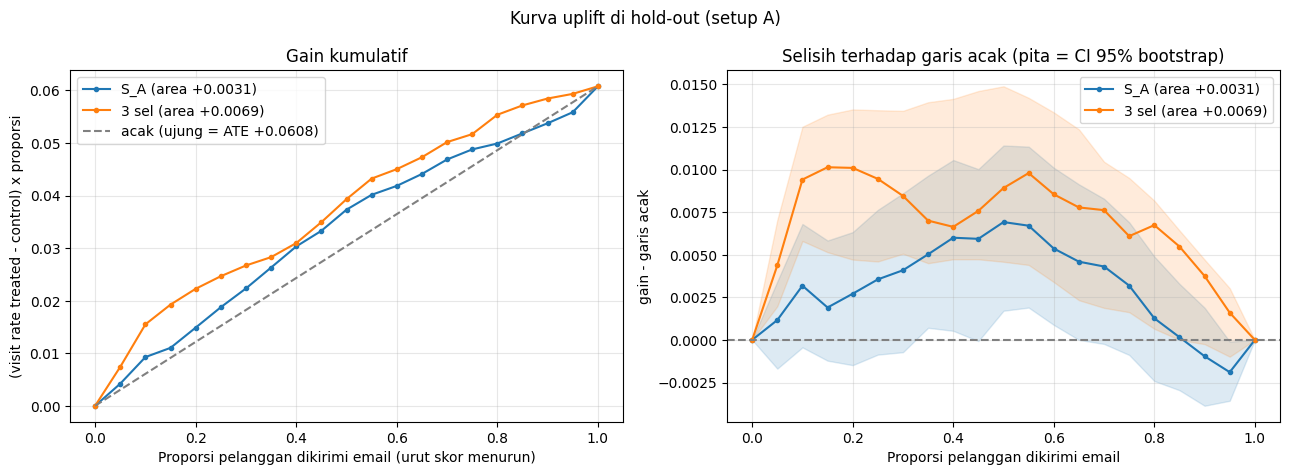

In [23]:
# ---- HOLD-OUT (jalankan SETELAH sel hold-out setup A; model = FE-3, seed 42) ----
fig_ho = plot_uplift(
    y_ho, treated_ho,
    {"S_A": S_A_ho, "3 sel": score3_ho},
    title="Kurva uplift di hold-out (setup A)")
plt.show()

Di dev (out-of-fold), tidak ada model yang terbukti mengurutkan pelanggan lebih baik dari tabel 3 sel. Ketiganya sedikit di atas urutan acak.

| Skor | Area |
| --- | --- |
| S-learner (S_A) | +0,0031 |
| Tabel 3 sel | +0,0069 |

Di hold-out, tabel 3 sel (area +0,0069) lebih baik daripada S_A (+0,0031), dengan selisih area -0,0037 [-0,0060; -0,0015] (S_A - tabel), kedua batas di bawah nol. Ini berbeda dari dev, tempat S_A (+0,0043) setara tabel (+0,0039). Tonjolan awal pada kurva tabel diduga berkaitan dengan sel (1,1) yang kebetulan lebih kuat di hold-out, tetapi dugaan ini belum diuji.

---
# Rangkuman Temuan Modeling

## 1. Hasil setup B: kirim apa ke siapa

### 1.1 Patokan sederhana

Arah selisih: pembanding dikurangi P1 (negatif = pembanding lebih rendah dari P1).

| Kebijakan | Dev | Hold-out | Selisih vs P1, dev | Selisih vs P1, hold-out |
|---|---:|---:|---:|---:|
| P0 Tidak kirim | 0,1061 | 0,1062 | -0,0766 | -0,0765 [-0,0878; -0,0636] |
| **P1 Mens ke semua** | 0,1828 | 0,1827 | patokan | patokan |
| P2 Womens ke semua | 0,1514 | 0,1513 | -0,0313 | -0,0314 [-0,0454; -0,0186] |
| P3 Tabel mens × womens | 0,1825 | tidak dinilai | -0,0003 [-0,0059; +0,0043] | - |

Di dev maupun hold-out, P1 lebih tinggi daripada P0 dan P2. Di hold-out, interval selisih keduanya tidak memuat nol, dan angkanya hampir sama dengan dev (misalnya P1 0,1828 di dev vs 0,1827 di hold-out), jadi pola ini bertahan di data yang belum pernah disentuh selama penjelajahan.

P3 hanya dinilai di dev. Selisihnya terhadap P1 hanya -0,0003 dengan interval yang memuat nol, jadi tidak terbukti lebih baik maupun lebih buruk. P1 dipilih atas P3 karena lebih sederhana, bukan karena terbukti unggul.

### 1.2 Model vs P1

**Tabel 1a: model vs P1 di dev (5 seed per baris)**

| Versi fitur | S_B: verdict | S_B: kisaran titik | T_B: verdict | T_B: kisaran titik |
|---|---|---|---|---|
| 7 fitur dasar | belum terbukti 5/5 | -0,0011 s/d +0,0013 | belum terbukti 4/5, kalah 1/5 | -0,0047 s/d -0,0025 |
| FE-1 history/recency | belum terbukti 5/5 | -0,0003 s/d +0,0006 | kalah 3/5 | -0,0055 s/d -0,0039 |
| FE-2 zip × channel | belum terbukti 5/5 | -0,0007 s/d +0,0012 | kalah 1/5 | -0,0048 s/d -0,0021 |
| FE-3 mens+womens | belum terbukti 5/5 | -0,0002 s/d +0,0017 | kalah 2/5 | -0,0049 s/d -0,0031 |

**Tabel 1b: hold-out (FE-3, seed 42, dilatih di seluruh dev)**

| Kebijakan | Hold-out | Selisih vs P1 |
|---|---:|---|
| P1 Mens ke semua | 0,1827 | patokan |
| S_B (S-learner, FE-3) | 0,1824 | -0,0003 [-0,0029; +0,0022] |

Tidak ada model yang menang atas P1 di satu pun seed, baik dengan fitur dasar maupun dengan tambahan FE. S-learner (S_B) berada di sekitar P1: titiknya berganti tanda antar seed dan besarnya setara pergeseran akibat seed (sekitar 0,0024), jadi S_B setara P1 tanpa bukti nilai tambah. T-learner (T_B) condong lebih buruk: titiknya negatif di semua seed dan kalah terbukti di sebagian seed. (S_B tampak unggul atas T_B di banyak seed, tetapi itu terutama karena T_B lemah, bukan bukti S_B unggul.)

Di hold-out, S_B vs P1 = -0,0003 [-0,0029; +0,0022], belum terbukti beda. Penyebabnya terlihat dari keputusannya: hanya 3,4% pelanggan yang dikirimi email Womens, jadi S_B praktis mengulang P1. (Di dev, bagian Womens dari S_B berkisar sekitar 4% sampai 12% tergantung versi dan seed, dan T_B sekitar 26%.)

Batas atas +0,0022 menyingkirkan keuntungan besar dari model, tetapi keuntungan yang sangat kecil tidak bisa dikesampingkan.

## 2. Hasil setup A: urutan skor kalau ada batas budget

Bagian ini menjawab pertanyaan yang berbeda dari bagian 2. Setup A menilai urutan skor (treated = Mens atau Womens, control = tanpa email) dan tidak membedakan email Mens dari Womens. Karena itu hasil di sini tidak menguji keputusan "kirim apa", dan ujung kanan kurva sepadan dengan email acak 50:50, bukan dengan P1. Setup A dinilai di hold-out setelah setup B; urutan ini dicatat di bagian Prosedur.

**Cara baca.** *Area kurva* adalah luas antara kurva uplift kumulatif dan garis acak: makin besar, makin baik skor itu mengurutkan pelanggan dari yang paling ke yang paling tidak terdorong oleh email.

**Tabel 2a: dev (patokan = skor 3 sel, cross-fit)**

| Skor | Area kurva | CI 95% |
|---|---:|---|
| Acak (kontrol negatif) | -0,0007 | [-0,0025; +0,0010] |
| Skor 3 sel (patokan) | +0,0039 | [+0,0019; +0,0056] |

| Perbandingan (model dikurangi 3 sel) | Verdict (5 seed) | Kisaran titik |
|---|---|---|
| S_A vs 3 sel | belum terbukti 5/5 | -0,0000 s/d +0,0005 |
| T_A vs 3 sel | belum terbukti 5/5 | -0,0009 s/d -0,0007 |

**Tabel 2b: hold-out (FE-3, seed 42, dilatih di seluruh dev)**

| Skor | Area kurva |
|---|---:|
| Acak | 0,0003 |
| Skor 3 sel | 0,0069 |
| S_A | 0,0031 |

S_A dikurangi 3 sel = -0,0037 [-0,0060; -0,0015] (negatif di kedua batas).

**Tabel 2c: per sel di hold-out**

| Sel (mens, womens) | n | Uplift hold-out | Rata-rata skor S_A | Tabel (dev) |
|---|---:|---:|---:|---:|
| (0,1) | 8.633 | 0,0625 | 0,0702 | 0,0765 |
| (1,0) | 8.655 | 0,0395 | 0,0428 | 0,0402 |
| (1,1) | 1.912 | 0,1546 | 0,0798 | 0,0809 |

Di dev, model tidak terbukti mengurutkan lebih baik daripada tabel 3 sel di seed mana pun; S_A kira-kira setara tabel, T_A sedikit di bawahnya. Di hold-out hasilnya berbeda: tabel lebih baik daripada S_A (-0,0037, interval tidak memuat nol). Penggaris sehat di hold-out, karena skor acak memberi area 0,0003, dekat nol.

Urutan sel sama di semua kolom tabel 2c: (1,1) > (0,1) > (1,0). Yang mencolok, uplift sel (1,1) di hold-out (0,1546) hampir dua kali nilai tabel dev (0,0809), selisih sekitar 2,5 sampai 3 SE, sehingga bisa saja kebetulan. Dugaan kami (belum diuji): tabel mengurutkan per blok, sedangkan skor S_A tumpang tindih antar sel karena fitur tambahan menambah variasi di dalam sel, sehingga saat sel (1,1) kebetulan kuat, S_A rugi lebih besar.

Kesimpulannya terbatas: model tidak terbukti lebih baik daripada tabel sederhana, baik di dev maupun di hold-out, dan sebagian keunggulan tabel di hold-out bisa berasal dari sel (1,1) yang kebetulan kuat. Hold-out hanya menilai satu model dengan satu seed.

## 3. Tuning: satu hyperparameter

Kami menguji satu hyperparameter, `min_child_samples` (1000, 200, dan 50), dengan 5 seed per nilai (15 jalan), hanya di dev dan tanpa memilih pemenang. Parameter ini mengatur seberapa konservatif model: makin besar nilainya, makin sulit pohon membuat cabang dari sedikit data. Tujuannya melihat apakah model menjadi lebih baik daripada P1 kalau dibuat lebih konservatif.

| min_child_samples | S_B vs P1 (rata-rata titik 5 seed) | T_B vs P1 (rata-rata titik 5 seed) | Share Womens S_B | Share Womens T_B |
|---|---|---|---|---|
| 1000 | ~+0,0009 | ~-0,0024 | ~8-10% | ~26% |
| 200 | ~+0,0009 | ~-0,0039 | ~5-7% | ~26-27% |
| 50 | ~+0,0005 | ~-0,0032 | ~4-7% | ~26-27% |

Tidak ada jalan yang plus-plus terhadap P1. S_B vs P1 selalu di kisaran noise pelatihan (sekitar 0,0024). T_B vs P1 tidak bergerak monoton terhadap knob ini. Bagian Womens dari S_B turun saat model lebih bebas, sedangkan T_B bertahan sekitar 26% dan sebabnya belum diketahui.

Hasil ini bukan dasar untuk mengganti pengaturan: hold-out memakai `min_child_samples` = 200 sesuai protokol yang dikunci sebelum hold-out dibuka. Sebagai pengecekan, hasil pada 200 cocok dengan tabel FE-3 di bagian 2.